Loaded imaging data shape: (2, 30, 128, 128, 1)
Labels shape: (2,)
Epoch 1/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step - accuracy: 1.0000 - loss: 0.6847 - val_accuracy: 1.0000 - val_loss: 1.4223e-08
Epoch 2/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 836ms/step - accuracy: 1.0000 - loss: 6.1934e-11 - val_accuracy: 1.0000 - val_loss: 2.2593e-29
Epoch 3/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 762ms/step - accuracy: 1.0000 - loss: 1.2732e-35 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 816ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 5/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 855ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 6/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 879ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 7/20
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 827ms/step - accuracy: 1.0000 - loss: 0.0000e+00 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Ep

/opt/anaconda3/lib/python3.12/site-packages/sklearn/metrics/_classification.py:386: UserWarning: A single label was found in 'y_true' and 'y_pred'. For the confusion matrix to have the correct shape, use the 'labels' parameter to pass all known labels.
  warnings.warn(


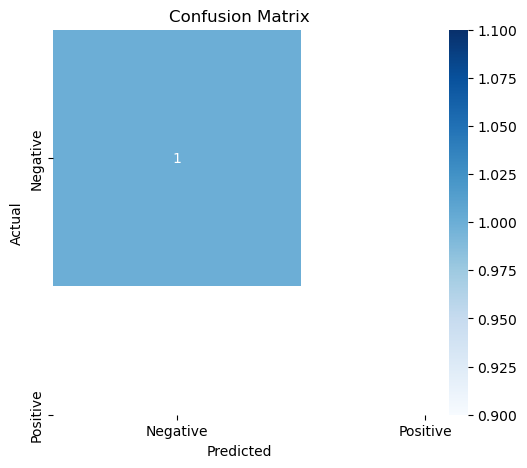

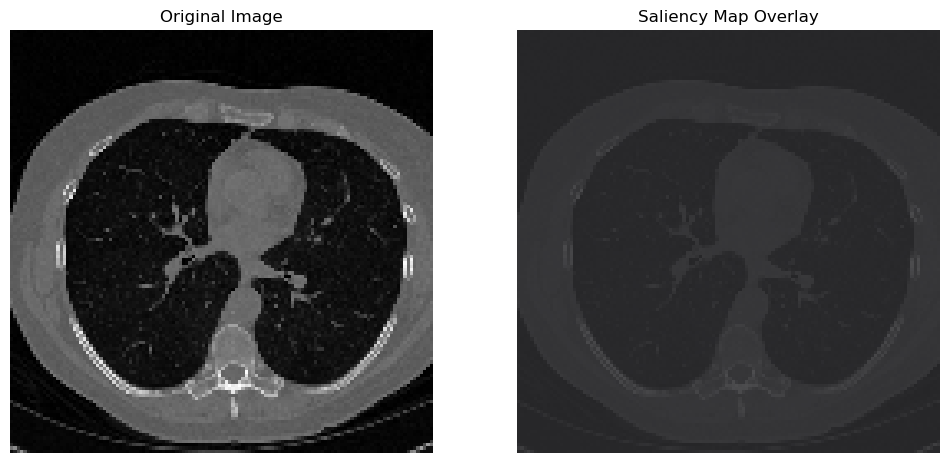

In [11]:
import os
import glob
import numpy as np
import pandas as pd
import pydicom
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Model
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import seaborn as sns

# Constants
IMG_SIZE = 128
NUM_SLICES = 30

# Function to load DICOM series
def load_dicom_series(series_path, target_size=(IMG_SIZE, IMG_SIZE), target_depth=NUM_SLICES):
    dicom_files = glob.glob(os.path.join(series_path, '*.dcm'))
    if not dicom_files:
        return None
    
    dicom_files = sorted(dicom_files)
    slices = []
    for dcm_file in dicom_files:
        try:
            ds = pydicom.dcmread(dcm_file)
            img = ds.pixel_array.astype(np.float32)
            img = (img - np.min(img)) / (np.max(img) - np.min(img) + 1e-6)
            img = cv2.resize(img, target_size)
            slices.append(img)
        except Exception:
            continue
    
    if not slices:
        return None
    
    slices = np.array(slices)
    current_depth = slices.shape[0]
    if current_depth != target_depth:
        indices = np.linspace(0, current_depth - 1, target_depth).astype(np.int32)
        slices = slices[indices, :, :]
    
    return np.expand_dims(slices, axis=-1)

# Load clinical data
clinical_df = pd.read_csv('Complete.csv')
clinical_df = clinical_df[~clinical_df['can_scr'].isin(["Post Screening", "Missed Screen"])]
clinical_df['DiagClass'] = clinical_df['can_scr'].map({'Negative': 0, 'Positive': 1})

# Load image data
X, y = [], []
patient_dirs = [d for d in os.listdir('.') if os.path.isdir(d) and d.isdigit()]
for patient_dir in patient_dirs:
    record = clinical_df[clinical_df['pid'].astype(str) == patient_dir]
    if record.empty:
        continue
    
    label = record['DiagClass'].values[0]
    patient_path = os.path.join('.', patient_dir)
    scan_sessions = sorted([d for d in os.listdir(patient_path) if os.path.isdir(os.path.join(patient_path, d))])
    if not scan_sessions:
        continue
    
    session_path = os.path.join(patient_path, scan_sessions[0])
    series_folders = [d for d in os.listdir(session_path) if d.startswith(('2', '3'))]
    if not series_folders:
        continue
    
    series_path = os.path.join(session_path, series_folders[0])
    volume = load_dicom_series(series_path)
    if volume is not None:
        X.append(volume)
        y.append(label)

X, y = np.array(X), np.array(y)
print("Loaded imaging data shape:", X.shape)
print("Labels shape:", y.shape)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define model
input_volume = layers.Input(shape=(NUM_SLICES, IMG_SIZE, IMG_SIZE, 1))
x = layers.TimeDistributed(layers.Lambda(lambda img: tf.image.grayscale_to_rgb(img)))(input_volume)

vgg_base = VGG16(include_top=False, weights='imagenet', input_shape=(IMG_SIZE, IMG_SIZE, 3))
for layer in vgg_base.layers[:-4]:
    layer.trainable = False
x = layers.TimeDistributed(vgg_base)(x)
x = layers.TimeDistributed(layers.GlobalAveragePooling2D())(x)
x = layers.GlobalAveragePooling1D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
output = layers.Dense(1, activation='sigmoid')(x)

model = Model(inputs=input_volume, outputs=output)
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train model
history = model.fit(X_train, y_train, epochs=20, batch_size=2, validation_data=(X_test, y_test))

# Confusion Matrix
plt.figure(figsize=(6, 5))
y_pred = (model.predict(X_test) > 0.5).astype(int)
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Negative', 'Positive'], yticklabels=['Negative', 'Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

# Generate Saliency Map for First Image
def generate_saliency_map(model, image):
    image = np.expand_dims(image, axis=0)
    image_tensor = tf.convert_to_tensor(image)
    with tf.GradientTape() as tape:
        tape.watch(image_tensor)
        prediction = model(image_tensor, training=False)
    grads = tape.gradient(prediction, image_tensor)
    saliency = np.abs(grads.numpy()).max(axis=-1)[0]  # Aggregate across color channels
    return saliency

first_image = X_test[0]
saliency_map = generate_saliency_map(model, first_image)

# Plot Saliency Map
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
ax[0].imshow(first_image[NUM_SLICES // 2, :, :, 0], cmap='gray')
ax[0].set_title("Original Image")
ax[0].axis("off")
ax[1].imshow(first_image[NUM_SLICES // 2, :, :, 0], cmap='gray', alpha=0.5)
ax[1].imshow(saliency_map[NUM_SLICES // 2, :, :], cmap='inferno', alpha=0.7)
ax[1].set_title("Saliency Map Overlay")
ax[1].axis("off")
plt.show()
